## **Exploratory Data Analysis (EDA)**

Open Source Datasets ბმულები:

- [UCI](https://archive.ics.uci.edu/)

- [kaggle](https://www.kaggle.com/datasets)

- [OpenML](https://www.openml.org)

- [Google Dataset Search](https://datasetsearch.research.google.com/)  

- [Awesome Public Datasets (GitHub Repository)](https://github.com/awesomedata/awesome-public-datasets)  

- [Data.gov](https://www.data.gov/) 

- [European Union Open Data Portal](https://data.europa.eu/euodp/en/data)

- [World Bank Open Data](https://data.worldbank.org/)

In [1]:
import numpy as np        
import pandas as pd         
import seaborn as sns  
import matplotlib.pyplot as plt
from sklearn.impute import SimpleImputer     # არასრული მონაცემების შევსებისათვის (imputation) 
from sklearn.preprocessing import MinMaxScaler, StandardScaler # მონაცემთა ნორმალიზაციის / სტანდარტიზაციისათვის
from sklearn.preprocessing import LabelEncoder, OneHotEncoder # კატეგორიული მახასიათებლების კოდირებისათვის

### Iris flower data set

<img src="../../images/iris.png" alt="iris" width="700">

* Features (მახასიათებლები)
    * Sepal length
    * Sepal width
    * Petal lengthh
    * petal width
* Target (სამიზნე ცვლადი)
    * species

In [2]:
# UCI Iris Dataset (Open Source)
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/iris/iris.data" # ბმული, სადაც მონაცემებია განთავსებული
columns = ["sepal_length", "sepal_width", "petal_length", "petal_width", "species"] # სვეტების სახელები

# გადმოვწერთ Iris მონაცემთა ნაკრებს URL-დან, გადავცემთ სვეტების სახელებს
df_iris = pd.read_csv(url, header=None, names=columns)

In [3]:
# ჩავტვირთავთ Iris dataset seaborn-ის მეშვეობით
df_iris = sns.load_dataset("iris")
df_iris.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [4]:
# DataFrame-ის ფორმა
df_iris.shape

(150, 5)

In [5]:
# მონაცემთა ტიპის შემოწმება
df_iris.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB


In [6]:
# მონაცემთა ტიპის შემოწმება
df_iris.dtypes

sepal_length    float64
sepal_width     float64
petal_length    float64
petal_width     float64
species          object
dtype: object

In [7]:
# missing მონაცემების შემოწმება
df_iris.isnull().sum()

sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64

In [8]:
# მაგალითად, შევქმნით არასრულ მონაცემებს
df_iris_missing = df_iris.copy()
np.random.seed(42)
missing_indices = np.random.choice(df_iris_missing.index, size=10, replace=False)
df_iris_missing.loc[missing_indices, "sepal_length"] = np.nan
df_iris_missing[df_iris_missing["sepal_length"].isna()]

# რამდენი None ჩანაწერია თითოეულ სვეტში
print(df_iris_missing.isnull().sum())

sepal_length    10
sepal_width      0
petal_length     0
petal_width      0
species          0
dtype: int64


In [9]:
# შევსება საშუალო მნიშვნელობით
# df_iris_missing["sepal_length"].fillna(df_iris_missing["sepal_length"].mean(), inplace=True)

# Mean imputation
imputer = SimpleImputer(strategy="mean") # strategy="median" (Median imputation)
df_iris_missing["sepal_length"] = imputer.fit_transform(df_iris_missing[["sepal_length"]])

print(df_iris_missing.isnull().sum())

sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64


In [10]:
# განმეორებითი მონაცემების რაოდენობა
print(df_iris.duplicated().sum())

1


In [11]:
# განმეორებითი ჩანაწერების წაშლა და in-place განახლება
df_iris.drop_duplicates(inplace=True)

In [12]:
df_iris.shape

(149, 5)

In [13]:
# ეს ბრძანება გამოიტანს "species" სვეტის უნიკალური მნიშვნელობების რაოდენობას
counts = df_iris["species"].value_counts()
counts

species
setosa        50
versicolor    50
virginica     49
Name: count, dtype: int64

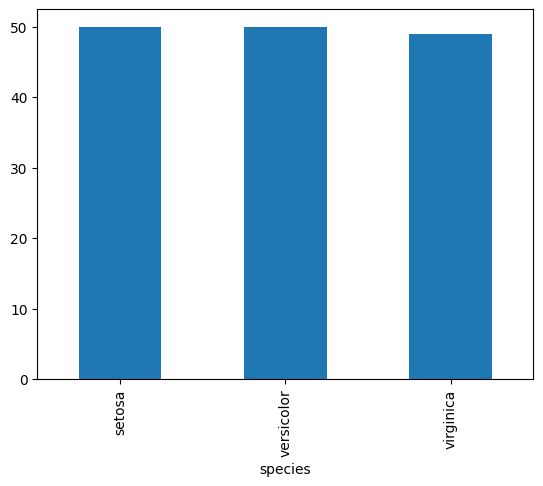

In [14]:
# bar გრაფიკის შექმნა რაოდენობებისთვის
counts.plot.bar();

In [15]:
# სტატისტიკის ჩვენება
df_iris.describe()

,sepal_length,sepal_width,petal_length,petal_width
count,149.000000,149.000000,149.000000,149.000000
mean,5.843624,3.059732,3.748993,1.194631
std,0.830851,0.436342,1.767791,0.762622
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.300000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


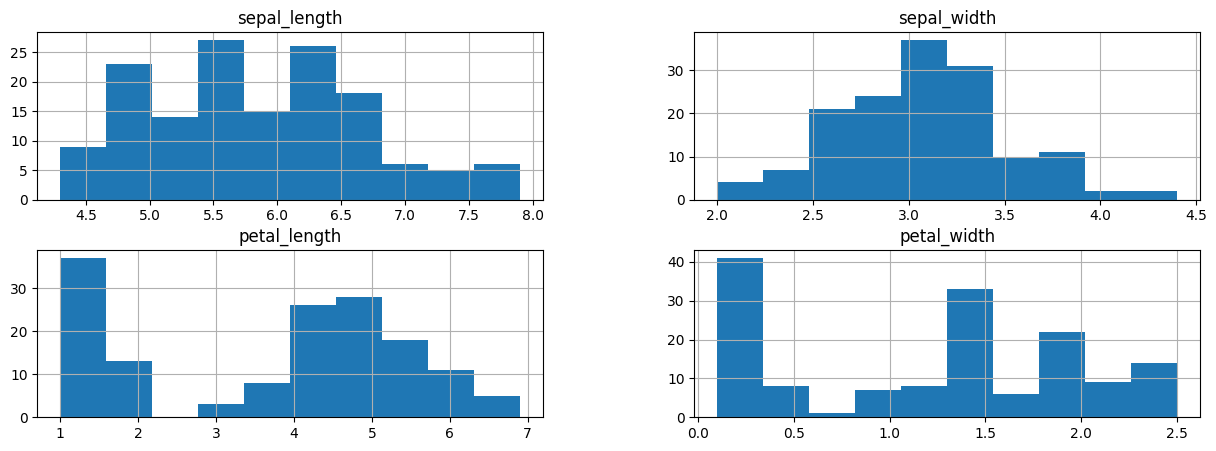

In [16]:
# ეს ბრძანება გვაძლევს ჰისტოგრამებს, იმის სანახავად თუ როგორია მონაცემთა განაწილება
df_iris.hist(figsize=(15,5));

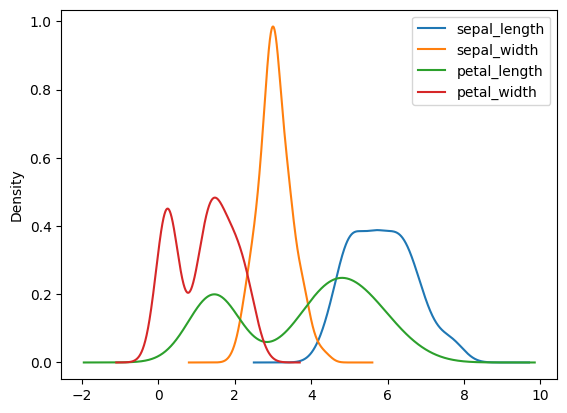

In [17]:
# თითოეული მახასიათებლის სიდიდის განაწილება
df_iris.plot.kde();

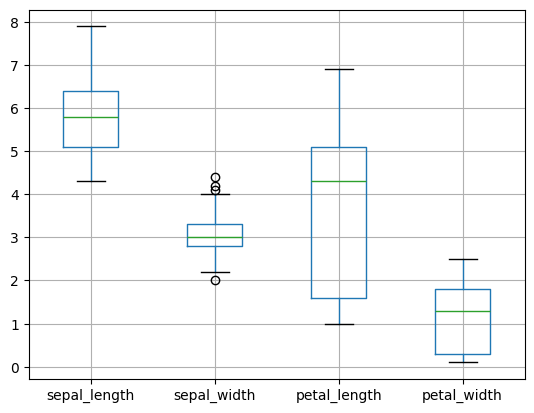

In [18]:
# ეს ბრძანება გვაძლევს ვიზუალიზაციას მონაცემთა განაწილებისა, outlier-ების და მედიანის შესახებ
df_iris.boxplot();

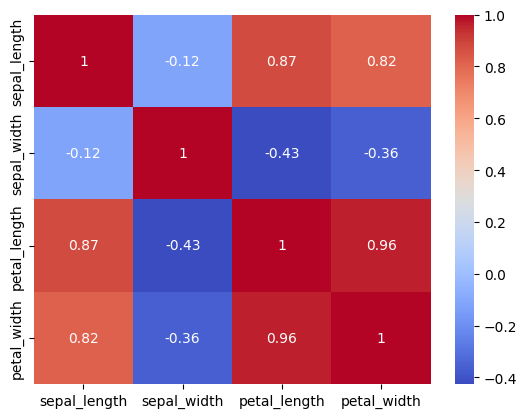

In [19]:
# Correlation
sns.heatmap(df_iris.drop("species", axis=1).corr(), annot=True, cmap="coolwarm");

In [20]:
# str ტიპის სვეტს "species" გადაიყვანს კატეგორიულად
df_iris["species"].astype("category").cat.codes

0      0
1      0
2      0
3      0
4      0
      ..
145    2
146    2
147    2
148    2
149    2
Length: 149, dtype: int8

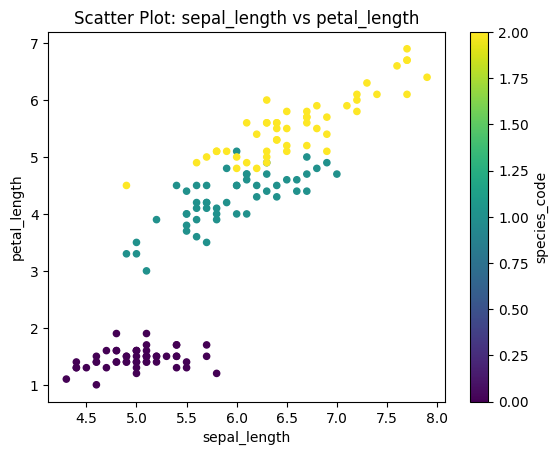

In [21]:
# ფერის მისაცემად გამოვიყენებთ თუ რომელ კატეგორიას ეკუთვნის
df_iris["species_code"] = df_iris["species"].astype("category").cat.codes

# ორ მახასიათებელს შორის ურთიერთობა
df_iris.plot.scatter(x="sepal_length", y="petal_length", c="species_code", colormap="viridis", title="Scatter Plot: sepal_length vs petal_length");

In [22]:
# მახასიათებლები
features = df_iris.columns[:4]
features

Index(['sepal_length', 'sepal_width', 'petal_length', 'petal_width'], dtype='object')

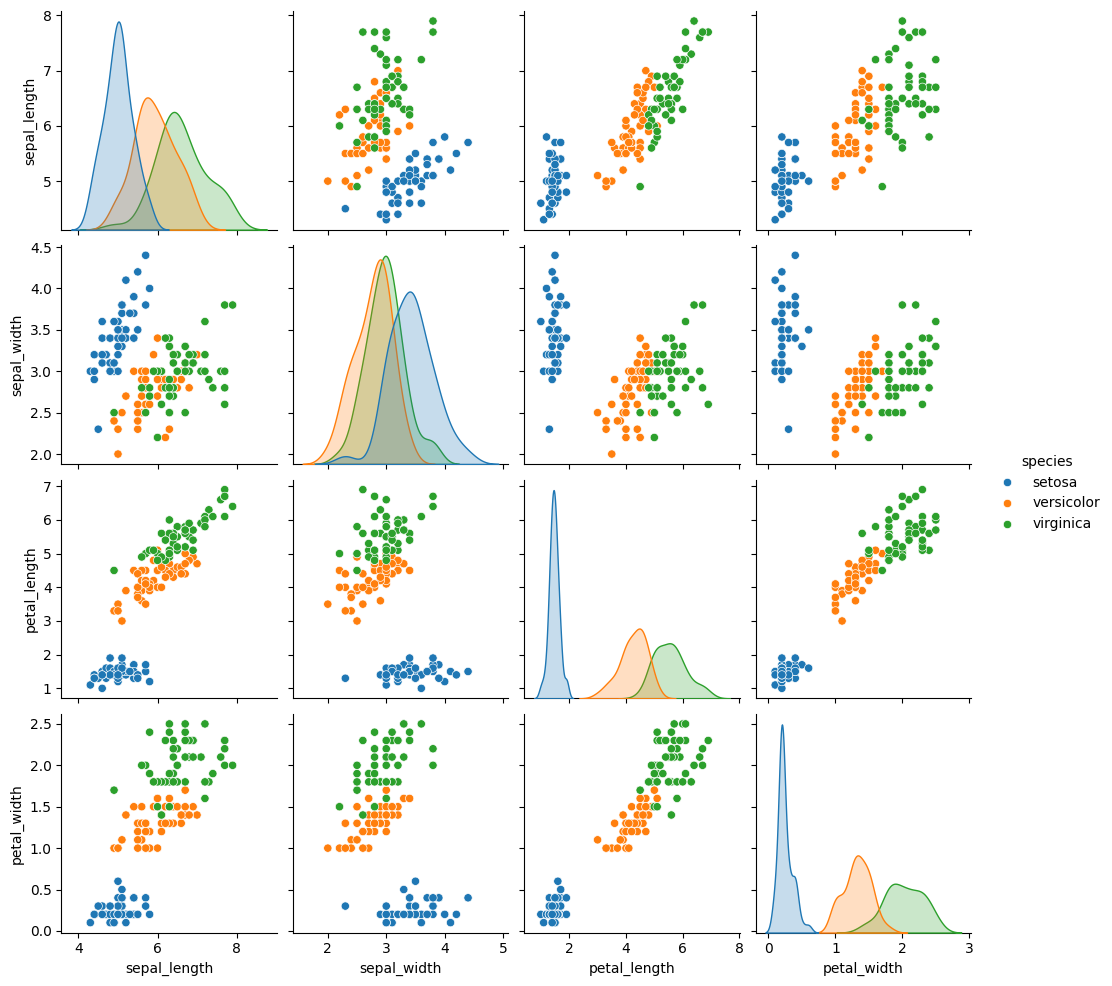

In [23]:
# მახასიათებლებს შორის ურთიერთობა, ვიზუალიზაცია seaborn-ის საშუალებით
sns.pairplot(df_iris, vars=features, hue="species");

In [24]:
# აგგრეგაცია სახეობის მიხედვით
df_iris.groupby("species").agg(["mean", "median"]) #df_iris.groupby("species").mean()

sepal_length        sepal_width        petal_length         \
                   mean median        mean median         mean median   
species                                                                 
setosa         5.006000    5.0    3.428000    3.4     1.462000   1.50   
versicolor     5.936000    5.9    2.770000    2.8     4.260000   4.35   
virginica      6.604082    6.5    2.979592    3.0     5.561224   5.60   

           petal_width        species_code         
                  mean median         mean median  
species                                            
setosa        0.246000    0.2          0.0    0.0  
versicolor    1.326000    1.3          1.0    1.0  
virginica     2.028571    2.0          2.0    2.0

| მეთოდი                               | მიზანი                                                                       | ფორმულა                                        |  როდის გამოვიყენოთ                                                       |
| ------------------------------------ | ---------------------------------------------------------------------------- | ---------------------------------------------- |  ----------------------------------------------------------------------- |
| **ნორმალიზაცია (Normalization)**     | მახასიათებლების მნიშვნელობების გადაყვანა ფიქსირებულ დიაპაზონში (ჩვეულებრივ [0, 1]) | $ x' = \frac{x - x_{min}}{x_{max} - x_{min}} $        | როცა სხვადასხვა ერთეულები გვაქვს (მაგ. ასაკი წლებში, შემოსავალი ევროში) |
| **სტანდარტიზაცია (Standardization)** | მახასიათებლების მნიშვნელობების გადაყვანა, ისე რომ საშუალო=0 და სტანდარტული გადახრა=1             | $x' = \frac{x - \mu}{\sigma} $                   | როცა ალგორითმი ეყრდნობა ნორმალურ განაწილებას (მაგ. PCA, SVM, რეგრესია)  |


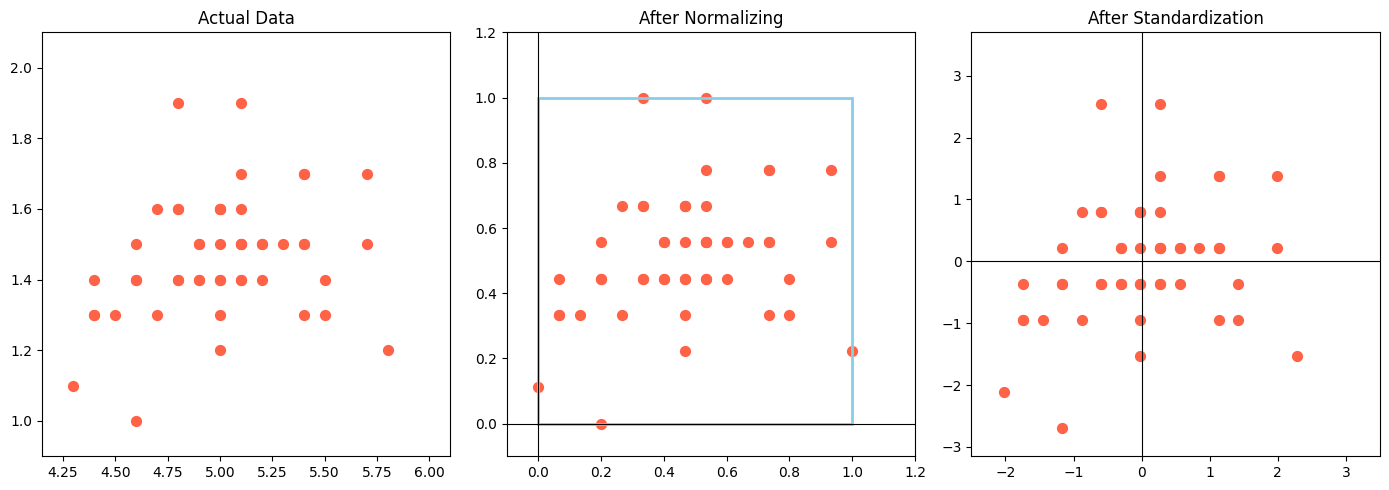

In [25]:
X = df_iris[df_iris["species"] == "setosa"][["sepal_length", "petal_length"]].values
X_norm = MinMaxScaler().fit_transform(X)
X_std = StandardScaler().fit_transform(X)

fig, axes = plt.subplots(1, 3, figsize=(14, 5))

axes[0].scatter(X[:, 0], X[:, 1], color='tomato', s=50)
axes[0].set_title("Actual Data")
axes[0].set_xlim(4.15, 6.1)
axes[0].axhline(0, color="black", lw=0.8)
axes[0].axvline(0, color="black", lw=0.8)
axes[0].set_ylim(0.9, 2.1)

axes[1].scatter(X_norm[:, 0], X_norm[:, 1], color='tomato', s=50)
axes[1].set_title("After Normalizing")
axes[1].set_xlim(-0.1, 1.2)
axes[1].set_ylim(-0.1, 1.2)
axes[1].axhline(0, color="black", lw=0.8)
axes[1].axvline(0, color="black", lw=0.8)
axes[1].add_patch(plt.Rectangle((0, 0), 1, 1, fill=False, ec="skyblue", lw=2))

axes[2].scatter(X_std[:, 0], X_std[:, 1], color='tomato', s=50)
axes[2].set_title("After Standardization")
axes[2].axhline(0, color="black", lw=0.8)
axes[2].axvline(0, color="black", lw=0.8)
axes[2].set_xlim(-2.5, 3.5)
axes[2].set_ylim(-3.15, 3.7)

plt.tight_layout()
plt.show()

In [26]:
# --- ნორმალიზაცია ---
minmax_scaler = MinMaxScaler()
df_normalized = pd.DataFrame(minmax_scaler.fit_transform(df_iris[features]), columns=features)
df_normalized.describe()

,sepal_length,sepal_width,petal_length,petal_width
count,149.000000,149.000000,149.000000,149.000000
mean,0.428784,0.441555,0.465931,0.456096
std,0.230792,0.181809,0.299626,0.317759
min,0.000000,0.000000,0.000000,0.000000
25%,0.222222,0.333333,0.101695,0.083333
50%,0.416667,0.416667,0.559322,0.500000
75%,0.583333,0.541667,0.694915,0.708333
max,1.000000,1.000000,1.000000,1.000000


In [27]:
# --- სტანდარტიზაცია ---
std_scaler = StandardScaler()
df_standardized = pd.DataFrame(std_scaler.fit_transform(df_iris[features]), columns=features)
df_standardized.describe().round(2)

,sepal_length,sepal_width,petal_length,petal_width
count,149.00,149.00,149.00,149.00
mean,0.00,0.00,-0.00,-0.00
std,1.00,1.00,1.00,1.00
min,-1.86,-2.44,-1.56,-1.44
25%,-0.90,-0.60,-1.22,-1.18
50%,-0.05,-0.14,0.31,0.14
75%,0.67,0.55,0.77,0.80
max,2.48,3.08,1.79,1.72


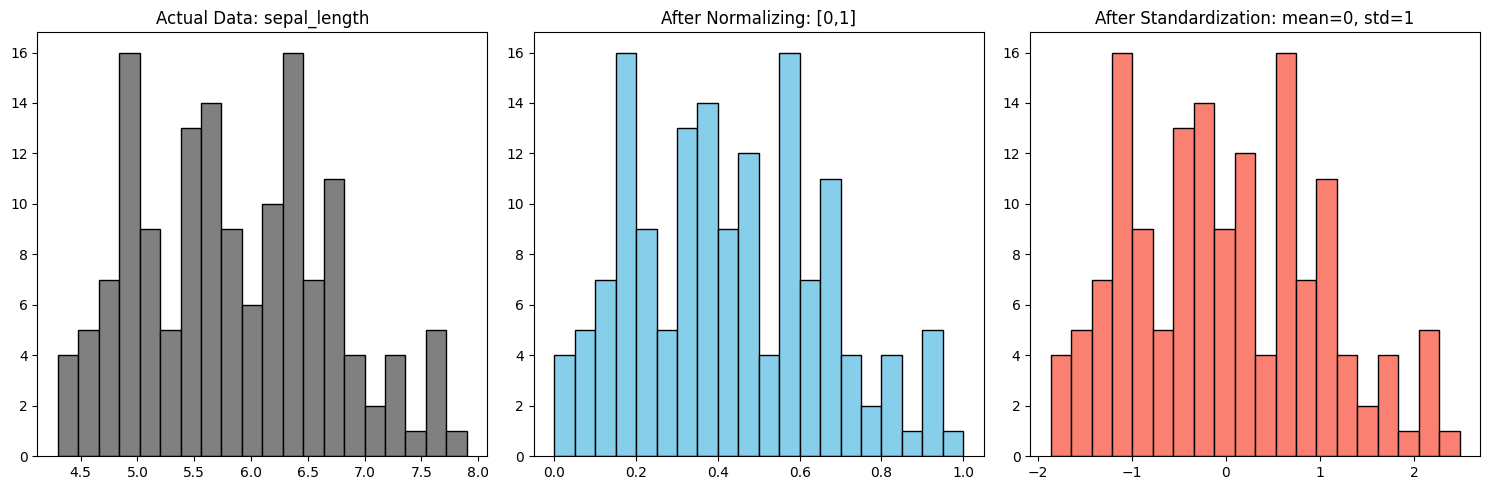

In [28]:
fig, ax = plt.subplots(1, 3, figsize=(15, 5))

ax[0].hist(df_iris["sepal_length"], bins=20, color="gray", edgecolor="black")
ax[0].set_title("Actual Data: sepal_length")

ax[1].hist(df_normalized["sepal_length"], bins=20, color="skyblue", edgecolor="black")
ax[1].set_title("After Normalizing: [0,1]")

ax[2].hist(df_standardized["sepal_length"], bins=20, color="salmon", edgecolor="black")
ax[2].set_title("After Standardization: mean=0, std=1")

fig.tight_layout()
plt.show()

### Titanic Dataset (Kaggle)

In [29]:
# Titanic Dataset მონაცემების ჩატვირთვა
url_titanic = "https://web.stanford.edu/class/archive/cs/cs109/cs109.1166/stuff/titanic.csv"
df_titanic = pd.read_csv(url_titanic)
df_titanic.head()

,Survived,Pclass,Name,Sex,Age,Siblings/Spouses Aboard,Parents/Children Aboard,Fare
0,0,3,Mr. Owen Harris Braund,male,22.0,1,0,7.2500
1,1,1,Mrs. John Bradley (Florence Briggs Thayer) Cum...,female,38.0,1,0,71.2833
2,1,3,Miss. Laina Heikkinen,female,26.0,0,0,7.9250
3,1,1,Mrs. Jacques Heath (Lily May Peel) Futrelle,female,35.0,1,0,53.1000
4,0,3,Mr. William Henry Allen,male,35.0,0,0,8.0500


In [30]:
# DataFrame-ის ფორმა
df_titanic.shape

(887, 8)

In [31]:
# მონაცემთა ტიპის შემოწმება
df_titanic.dtypes

Survived                     int64
Pclass                       int64
Name                        object
Sex                         object
Age                        float64
Siblings/Spouses Aboard      int64
Parents/Children Aboard      int64
Fare                       float64
dtype: object

In [32]:
# missing მონაცემების შემოწმება
df_titanic.isnull().sum()

Survived                   0
Pclass                     0
Name                       0
Sex                        0
Age                        0
Siblings/Spouses Aboard    0
Parents/Children Aboard    0
Fare                       0
dtype: int64

In [33]:
# განმეორებითი მონაცემების რაოდენობა
print(df_titanic.duplicated().sum())

0


In [34]:
# სტატისტიკის ჩვენება
df_titanic.describe()

,Survived,Pclass,Age,Siblings/Spouses Aboard,Parents/Children Aboard,Fare
count,887.000000,887.000000,887.000000,887.000000,887.000000,887.00000
mean,0.385569,2.305524,29.471443,0.525366,0.383315,32.30542
std,0.487004,0.836662,14.121908,1.104669,0.807466,49.78204
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.00000
25%,0.000000,2.000000,20.250000,0.000000,0.000000,7.92500
50%,0.000000,3.000000,28.000000,0.000000,0.000000,14.45420
75%,1.000000,3.000000,38.000000,1.000000,0.000000,31.13750
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.32920


In [35]:
df_titanic.describe(include="object")

,Name,Sex
count,887,887
unique,887,2
top,Mr. Owen Harris Braund,male
freq,1,573


In [36]:
print(df_titanic["Sex"].unique())

['male' 'female']


| მეთოდი                          | აღწერა                                             | მაგალითი                                    | ბიბლიოთეკა                            | როდის არ გამოვიყენოთ                                                   |
| ------------------------------- | -------------------------------------------------- | ------------------------------------------- | ------------------------------------- | ---------------------------------------------------------------------- |
| Label Encoding            | თითოეული უნიკალური კატეგორია → რიცხვი (0, 1, 2...) | `{"male":0, "female":1}`                    | `LabelEncoder`                        |როცა ალგორითმი ეყრდნობა მანძილს ან ხაზოვნებას (KNN, Linear Regression) |
| One-Hot Encoding            | ქმნის ახალ ბინარულ სვეტს ყოველი კატეგორიისთვის     | `sex_male`, `sex_female`, ... | `pd.get_dummies()` ან `OneHotEncoder` |როცა კატეგორიები ძალიან ბევრია (ბევრი ახალი სვეტი შეიქმნება)           |
| Ordinal Encoding            | გამოიყენება როცა კატეგორიებს აქვთ რიგითობა         | `{"Low":1, "Medium":2, "High":3}`           | `OrdinalEncoder`                      |როცა თანმიმდევრობა არ არსებობს                                         |


In [37]:
# str ტიპის სვეტს "Sex" გადაიყვანს კატეგორიულად
df_titanic["Sex"].astype("category").cat.codes

0      1
1      0
2      0
3      0
4      1
      ..
882    1
883    0
884    0
885    1
886    1
Length: 887, dtype: int8

In [38]:
label_encoder = LabelEncoder()
df_titanic["Sex_label"] = label_encoder.fit_transform(df_titanic["Sex"])

df_titanic[["Sex", "Sex_label"]].head()

,Sex,Sex_label
0,male,1
1,female,0
2,female,0
3,female,0
4,male,1


In [39]:
# ფუნქცია თითოეული უნიკალური მნიშვნელობისთვის ქმნის ცალკე სვეტს, მნიშვნელობა არის 1, თუ ჩანაწერში აღნიშნული კატეგორია არსებობს, 0 - თუ არა
pd.get_dummies(df_titanic["Sex"])

,female,male
0,False,True
1,True,False
2,True,False
3,True,False
4,False,True
...,...,...
882,False,True
883,True,False
884,True,False
885,False,True


In [40]:
encoder = OneHotEncoder(sparse_output=False, drop=None) 
X_encoded = encoder.fit_transform(df_titanic[["Sex"]])

pd.DataFrame(X_encoded, columns=encoder.get_feature_names_out(["Sex"]))

,Sex_female,Sex_male
0,0.0,1.0
1,1.0,0.0
2,1.0,0.0
3,1.0,0.0
4,0.0,1.0
...,...,...
882,0.0,1.0
883,1.0,0.0
884,1.0,0.0
885,0.0,1.0


In [41]:
# ეს ბრძანება გამოიტანს "Survived" სვეტის უნიკალური მნიშვნელობების რაოდენობას
survived_counts = df_titanic["Survived"].value_counts()
survived_counts

Survived
0    545
1    342
Name: count, dtype: int64

In [42]:
# ეს ბრძანება გამოიტანს "Pclass" სვეტის უნიკალური მნიშვნელობების რაოდენობას
class_counts = df_titanic["Pclass"].value_counts()
class_counts

Pclass
3    487
1    216
2    184
Name: count, dtype: int64

In [43]:
# DataFrame-ს მონაცემები ჯგუფდება "Pclass" სვეტის მიხედვით
df_titanic.groupby("Pclass")[["Age", "Siblings/Spouses Aboard", "Sex_label", "Parents/Children Aboard", "Fare"]].mean()

,Age,Siblings/Spouses Aboard,Sex_label,Parents/Children Aboard,Fare
Pclass,,,,,
1,38.788981,0.416667,0.564815,0.356481,84.154687
2,29.868641,0.402174,0.586957,0.380435,20.662183
3,25.188747,0.620123,0.704312,0.396304,13.707707


In [44]:
# DataFrame-ს მონაცემები ჯგუფდება "Survived" სვეტის მიხედვით
df_titanic.groupby("Survived")[["Pclass", "Age", "Sex_label"]].mean()

,Pclass,Age,Sex_label
Survived,,,
0,2.528440,30.138532,0.851376
1,1.950292,28.408392,0.318713


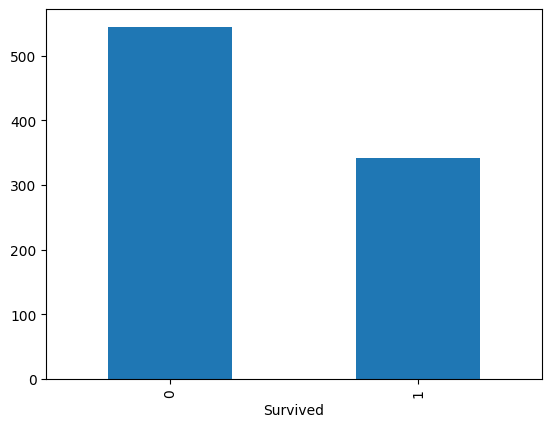

In [45]:
# bar გრაფიკის შექმნა რაოდენობებისთვის
survived_counts.plot.bar();

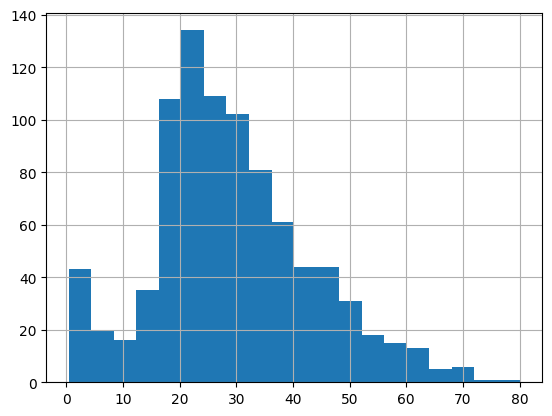

In [46]:
# ეს ბრძანება გვაძლევს ჰისტოგრამს, იმის სანახავად თუ როგორია "Age" სვეტის განაწილება
df_titanic["Age"].hist(bins=20);

<Axes: xlabel='Age_group', ylabel='Survived'>

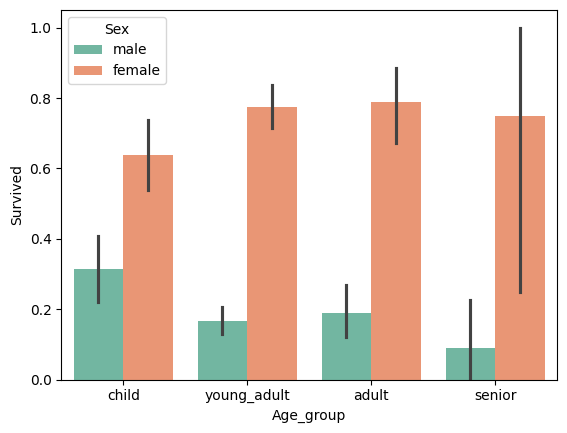

In [47]:
# შევქმნათ კატეგორიული ტიპის სვეტი 
df_titanic["Age_group"] = pd.cut(
    df_titanic["Age"],
    bins=[0, 18, 40, 60, 80],
    labels=["child", "young_adult", "adult", "senior"]
)
sns.barplot(x="Age_group", y="Survived", hue="Sex", data=df_titanic, palette="Set2")

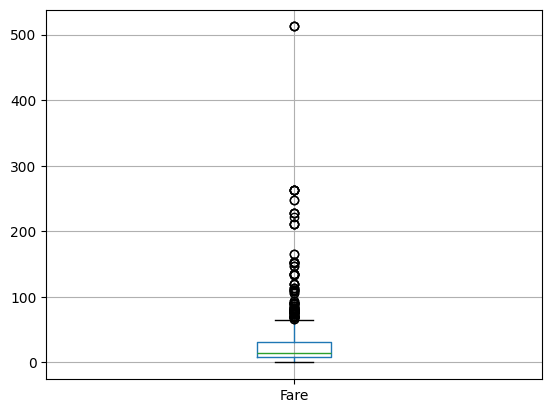

In [48]:
# ეს ბრძანება გვაძლევს ვიზუალიზაციას მონაცემთა განაწილებისა, outlier-ების და მედიანის შესახებ
df_titanic[["Fare"]].boxplot();

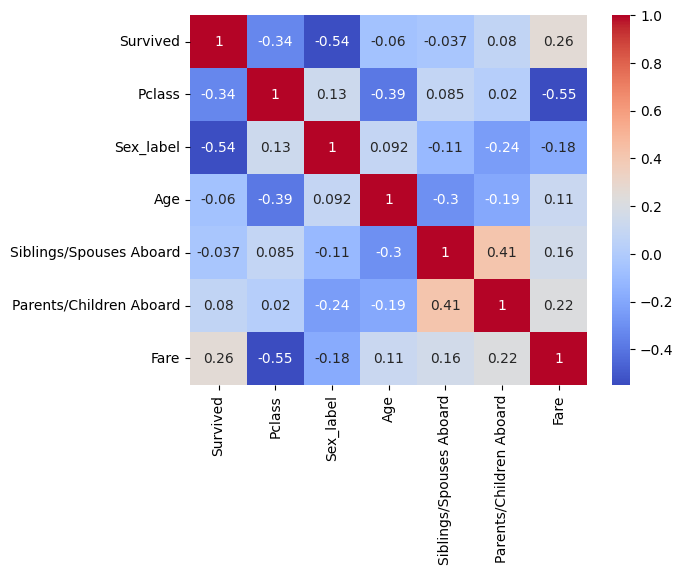

In [50]:
# Correlation
sns.heatmap(df_titanic[['Survived', 'Pclass', 'Sex_label', 'Age', 'Siblings/Spouses Aboard', 'Parents/Children Aboard', 'Fare']].corr(), annot=True, cmap="coolwarm");

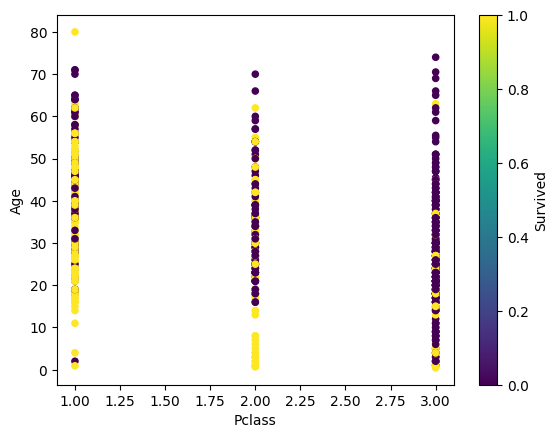

In [51]:
# ორ მახასიათებელს შორის ურთიერთობა
df_titanic.plot.scatter(x="Pclass", y="Age", c="Survived", colormap="viridis");

In [52]:
# მახასიათებლები
features = df_titanic.drop("Name", axis=1).columns[1:]
features

Index(['Pclass', 'Sex', 'Age', 'Siblings/Spouses Aboard',
       'Parents/Children Aboard', 'Fare', 'Sex_label', 'Age_group'],
      dtype='object')

In [53]:
df_titanic[(df_titanic["Survived"] == 0) & (df_titanic["Sex"] == "female")]["Pclass"].value_counts()

Pclass
3    72
2     6
1     3
Name: count, dtype: int64